# Choosing adjustment variables from chronological evidence

The protocol is an ordered record of seven research stages:

$$
\mathcal P=(S_1,S_2,S_3,S_4,S_5,S_6,S_7).
$$

Here, $\mathcal P$ is the complete protocol record; $S_1$ is variable selection; $S_2$ is causal discovery; $S_3$ is causal adjustment; $S_4$ is explanatory and predictive assessment; $S_5$ is portfolio construction; $S_6$ is backtesting; and $S_7$ is multiple-testing adjustment.

## Packages and notebook settings

In [ ]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("10_causal_factor_protocol");
using CSV,TOML,Printf,Distributions
using RiskLabAI.CausalFactorAnalysis
include(joinpath("..","support","CausalNotebookTools.jl"))
using .CausalNotebookTools
include(joinpath("..","support","BookCausalStudy.jl"))
using .BookCausalStudy
import .BookCausalStudy: frame
include(joinpath("..","support","BookIdentificationStudy.jl"))
using .BookIdentificationStudy: PrimitiveStore,normal_block
include(joinpath("..","support","BookProtocolStudy.jl"))
using .BookProtocolStudy
default(left_margin=12Plots.mm,bottom_margin=10Plots.mm,right_margin=8Plots.mm)
store=PrimitiveStore(joinpath("..","data","chapter10_random_inputs"),"protocol")
captions=Dict("protocol_stage_order"=>("The seven protocol stages in their required order.","tab:chapter28-stage-order"),"protocol_provenance"=>("Source, family, and public-data facts used by the notebooks.","tab:chapter28-provenance"),"protocol_event_horizons"=>("Public-date event labels and their declared return horizons.","tab:chapter28-event-horizons"),"protocol_overlap_matrix"=>("Pairwise overlap indicators for the declared return horizons.","tab:chapter28-overlap-matrix"),"protocol_fold_membership"=>("Purged training and test membership for each fold.","tab:chapter28-fold-membership"),"protocol_embargo_sweep"=>("Acceptance across declared embargo lengths.","tab:chapter28-embargo-sweep"),"protocol_selection_methods"=>("Declared variable-selection methods and temporal-refit requirement.","tab:chapter28-selection-methods"),"protocol_selection_refits"=>("Recorded refits within each training fold.","tab:chapter28-selection-refits"),"protocol_graph_edges"=>("Directed edges in the supplied graph.","tab:chapter28-graph-edges"),"protocol_graph_assumptions"=>("Assumptions attached to the supplied graph.","tab:chapter28-graph-assumptions"),"protocol_graph_roles"=>("Declared graph roles and ordinary-control use.","tab:chapter28-graph-roles"),"protocol_adjustment_evidence"=>("Identification evidence for the supplied back-door adjustment.","tab:chapter28-adjustment-evidence"),"protocol_stage23_rejections"=>("Graph and adjustment declarations rejected by the released checks.","tab:chapter28-stage23-rejections"),"protocol_stage23_rejection_counts"=>("Rejected cases by protocol stage.","tab:chapter28-stage23-rejection-counts"),"protocol_section1_summary"=>("Questions answered by the first three protocol stages.","tab:chapter28-section1-summary"),"protocol_fold_evidence"=>("Foldwise fitting and prediction evidence.","tab:chapter28-fold-evidence"),"protocol_fold_refits"=>("Required training-only refits in every fold.","tab:chapter28-fold-refits"),"protocol_stage4_metrics"=>("Separate explanatory and predictive evidence records.","tab:chapter28-stage4-metrics"),"protocol_public_fold_metrics"=>("Foldwise public-return measures with a training-mean comparison rule.","tab:chapter28-public-fold-metrics"),"protocol_public_data"=>("Public-return source and foldwise illustration.","tab:chapter28-public-data"),"protocol_portfolio_requirements"=>("The six required portfolio considerations and their supplied evidence.","tab:chapter28-portfolio-requirements"),"protocol_public_strategy"=>("Observed public-return path before and after declared transaction costs.","tab:chapter28-public-strategy"),"protocol_public_weights"=>("Illustrative public-return weights used only to show a portfolio record.","tab:chapter28-public-weights"),"protocol_transfer_sensitivity"=>("Transfer from intended to achieved supplied exposures.","tab:chapter28-transfer-sensitivity"),"protocol_cpcv_folds"=>("Combinatorial path contributions in the supplied record.","tab:chapter28-cpcv-folds"),"protocol_cpcv_coverage"=>("Test contributions per event and complete path.","tab:chapter28-cpcv-coverage"),"protocol_public_trial_paths"=>("Observed public-return paths for the declared three-trial family.","tab:chapter28-public-trial-paths"),"protocol_monte_carlo_record"=>("A complete Monte Carlo backtest declaration.","tab:chapter28-monte-carlo-record"),"protocol_stage456_rejections"=>("Incomplete Stage 4, Stage 5, and Stage 6 records rejected by the released checks.","tab:chapter28-stage456-rejections"),"protocol_section2_summary"=>("Questions answered by Stages 4 through 6.","tab:chapter28-section2-summary"),"protocol_trial_family_identity"=>("The same declared trial family appears in Stages 6 and 7.","tab:chapter28-trial-family-identity"),"protocol_family_partitions"=>("The declared, disjoint partitions of the trial family.","tab:chapter28-family-partitions"),"protocol_partition_membership"=>("Trial membership in each declared family partition.","tab:chapter28-partition-membership"),"protocol_partition_checks"=>("Complete partition evidence is accepted and malformed partitions are rejected.","tab:chapter28-partition-checks"),"protocol_public_p_values"=>("Dependence-adjusted evidence from the three declared public-return paths.","tab:chapter28-public-p-values"),"protocol_public_adjustments"=>("Raw and adjusted values for the declared public-return trial family.","tab:chapter28-public-adjustments"),"protocol_adjustment_scope"=>("The distinct roles of the Stage 7 choices used or listed here.","tab:chapter28-adjustment-scope"),"protocol_dsr_inputs"=>("Declared inputs required for the deflated Sharpe calculation.","tab:chapter28-dsr-inputs"),"protocol_dsr_sensitivity"=>("Sensitivity of the selection benchmark to the effective trial count.","tab:chapter28-dsr-sensitivity"),"protocol_moment_grid"=>("Feasible and infeasible skewness-kurtosis pairs.","tab:chapter28-moment-grid"),"protocol_dependence_record"=>("Evidence required when trials and return observations are dependent.","tab:chapter28-dependence-record"),"protocol_trial_correlation"=>("Correlation among the three declared public-return paths.","tab:chapter28-trial-correlation"),"protocol_record_checks"=>("Immutability checks for the seven stage records and complete report.","tab:chapter28-record-checks"),"protocol_public_names"=>("All twelve released protocol names covered by the chapter notebooks.","tab:chapter28-public-names"),"protocol_stage7_rejections"=>("Incomplete or inconsistent Stage 7 records rejected by the released checks.","tab:chapter28-stage7-rejections"),"protocol_stage7_rejection_groups"=>("Rejected Stage 7 cases grouped by the missing or inconsistent evidence.","tab:chapter28-stage7-rejection-groups"),"protocol_section3_summary"=>("Questions answered by the Stage 7 evidence record.","tab:chapter28-section3-summary"));


## Seven ordered evidence stages

Row,Order,Stage,Record
,Int64,String,SubStrin…
1,1,Variable Selection,Variable Selection
2,2,Causal Discovery,Causal Discovery
3,3,Causal Adjustment Set,Causal Adjustment Set
4,4,Causal Explanatory and Predictive Power,Causal Explanatory And Predictive Power
5,5,Causal Portfolio Construction,Causal Portfolio Construction
6,6,Backtest,Backtest
7,7,Multiple Testing Adjustments,Multiple Testing Adjustments


Row,Item,Value
,String,Any
1,Source record,PROTOCOL-01
2,Source location,"PDF pages 18-22 (journal pages 27-31), Exhibit 10"
3,Trial family,declared-family
4,Declared trials,3
5,Public return observations,1760
6,Public return columns,49


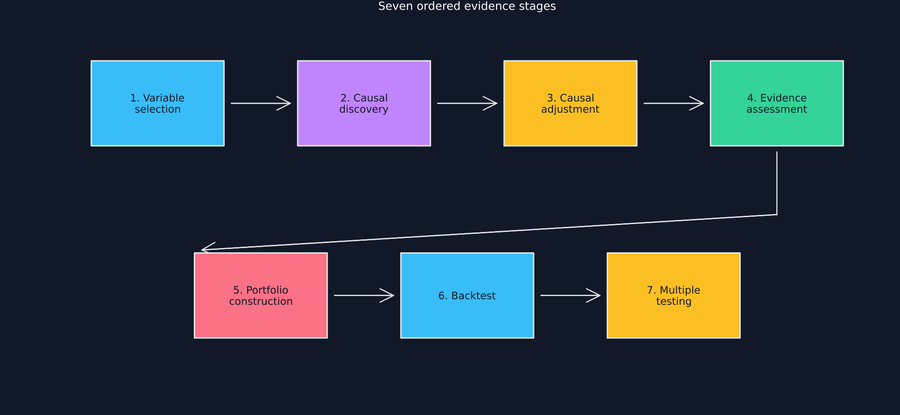

In [1]:
function table(values,name)
    shown=copy(values)
    for column in names(shown)
        if all(value->value isa Bool,shown[!,column])
            shown[!,column]=ifelse.(shown[!,column],"Yes","No")
        end
    end
    caption,label=captions[name]
    save_table(shown,paths,name;caption=caption,label=label)
    return nothing
end
dates,industry_names,industry_returns=protocol_returns()
observation_ids=Tuple("event-".*string.(dates[1:6]))
report=validate_causal_factor_protocol(valid_protocol_report(observation_ids))
stage_table=frame(["Order","Stage","Record"],[(index,name,strip(replace(record_name(stage)," Stage"=>""))) for (index,(name,stage)) in enumerate(report.stages)])
table(stage_table,"protocol_stage_order")
provenance_table=frame(["Item","Value"],[("Source record",report.source_oracle),("Source location",report.source_locator),("Trial family",report.trial_family_id),("Declared trials",length(report.declared_trial_ids)),("Public return observations",length(dates)),("Public return columns",size(industry_returns,2))])
table(provenance_table,"protocol_provenance")
stage_colors=[palette.cyan,violet,palette.amber,palette.green,palette.rose,palette.cyan,palette.amber]
stage_positions=[(.9,3.),(3.7,3.),(6.5,3.),(9.3,3.),(2.3,1.1),(5.1,1.1),(7.9,1.1)]
short_names=["Variable\nselection","Causal\ndiscovery","Causal\nadjustment","Evidence\nassessment","Portfolio\nconstruction","Backtest","Multiple\ntesting"]
figure=plot(;xlims=(-.4,10.6),ylims=(.35,3.75),axis=false,grid=false,legend=false,title="Seven ordered evidence stages",size=(1300,600))
for (index,(x,y)) in enumerate(stage_positions)
    plot!(figure,Shape([x-.9,x+.9,x+.9,x-.9],[y-.42,y-.42,y+.42,y+.42]);color=stage_colors[index],linecolor=palette.text,label="")
    annotate!(figure,x,y,text(string(index)*". "*short_names[index],10,palette.background,:center))
    if index in [1,2,3,5,6]
        next_x,next_y=stage_positions[index+1]
        plot!(figure,[x+1,next_x-1],[y,next_y];arrow=true,color=palette.text,linewidth=1.6,label="")
    elseif index==4
        plot!(figure,[x,x,1.5],[y-.48,1.9,1.55];arrow=true,color=palette.text,linewidth=1.6,label="")
    end
end
save_figure(figure,paths,"protocol_stage_flow")


## Aligning outcome horizons with fold boundaries

Two return horizons overlap when their half-open intervals share time:

$$
O_{ij}=\mathbf 1\!\left\{\max(s_i,s_j)<\min(e_i,e_j)\right\}.
$$

Here, $O_{ij}$ is one when events $i$ and $j$ overlap and zero otherwise; $s_i$ and $e_i$ are the start and end coordinates of event $i$; $s_j$ and $e_j$ are the corresponding coordinates for event $j$; and $\mathbf 1\{\cdot\}$ is the indicator function.

Row,Event,Public date label,Start coordinate,End coordinate,Length
,Int64,String,Float64,Float64,Float64
1,1,2019-01-02,0.0,2.0,2.0
2,2,2019-01-03,1.0,3.0,2.0
3,3,2019-01-04,4.0,5.0,1.0
4,4,2019-01-07,6.0,7.0,1.0
5,5,2019-01-08,8.0,9.0,1.0
6,6,2019-01-09,10.0,11.0,1.0


Row,Event,Event 1,Event 2,Event 3,Event 4,Event 5,Event 6
,String,Int64,Int64,Int64,Int64,Int64,Int64
1,Event 1,1,1,0,0,0,0
2,Event 2,1,1,0,0,0,0
3,Event 3,0,0,1,0,0,0
4,Event 4,0,0,0,1,0,0
5,Event 5,0,0,0,0,1,0
6,Event 6,0,0,0,0,0,1


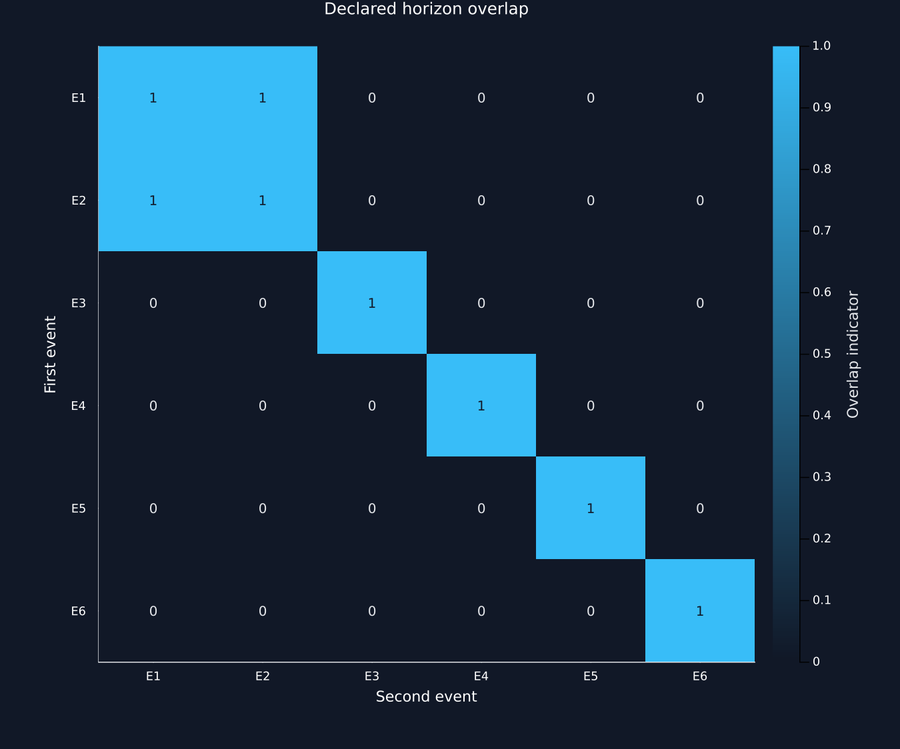

In [2]:
horizons=report.variable_selection.validation.event_horizons
horizon_table=frame(["Event","Public date label","Start coordinate","End coordinate","Length"],[(index,replace(item.observation_id,"event-"=>""),item.start,item.stop,item.stop-item.start) for (index,item) in enumerate(horizons)])
table(horizon_table,"protocol_event_horizons")
intervals=[(item.start,item.stop) for item in horizons]
overlap=[Int(max(left[1],right[1])<min(left[2],right[2])) for left in intervals,right in intervals]
overlap_frame=hcat(DataFrame("Event"=>["Event "*string(index) for index in 1:6]),DataFrame(overlap,["Event "*string(index) for index in 1:6]))
table(overlap_frame,"protocol_overlap_matrix")
figure=heatmap_record(overlap,["E"*string(index) for index in 1:6],["E"*string(index) for index in 1:6];title="Declared horizon overlap",xlabel="Second event",ylabel="First event",colorbar=true,colorbar_title="Overlap indicator",size=(900,750))
save_figure(figure,paths,"protocol_overlap_heatmap")


## Separating training observations around validation periods

The safe training set removes overlapping horizons and observations inside the post-test embargo:

$$
\mathcal T_k^{\mathrm{safe}}=\left\{i\in\mathcal T_k: [s_i,e_i)\cap[s_j,e_j)=\varnothing\ \text{and}\ s_i\notin[e_j,e_j+h)\ \text{for every }j\in\mathcal V_k\right\}.
$$

Here, $\mathcal T_k$ is the proposed training set for fold $k$; $\mathcal V_k$ is its test set; $[s_i,e_i)$ is a training horizon; $[s_j,e_j)$ is a test horizon; $h$ is the embargo length; and $\mathcal T_k^{\mathrm{safe}}$ is the retained training membership.

Row,Fold,Path,Training events,Test events,Refit record,Refit parts
,String,String,String,String,String,Int64
1,F1,P1,"3, 4, 5, 6","1, 2",R1,3
2,F2,P1,"1, 2, 5, 6","3, 4",R2,3
3,F3,P1,"1, 2, 3, 4","5, 6",R3,3


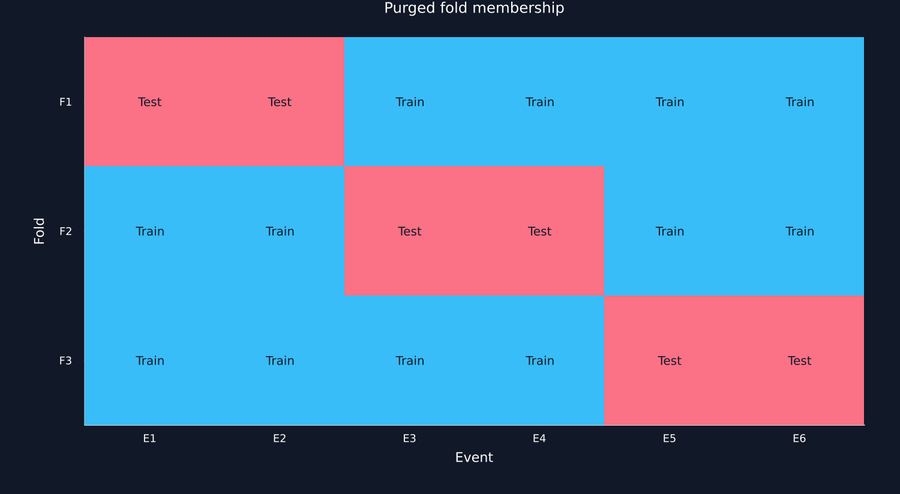

Row,Embargo,Result,Message,Accepted
,Float64,String,Abstract…,String
1,0.0,Rejected,Stage 1: strong time dependence requires an embargo,No
2,0.25,Accepted,Record satisfies the released checks,Yes
3,0.5,Accepted,Record satisfies the released checks,Yes
4,1.0,Accepted,Record satisfies the released checks,Yes
5,1.25,Rejected,Stage 1: post-test embargo observations must be excluded,No


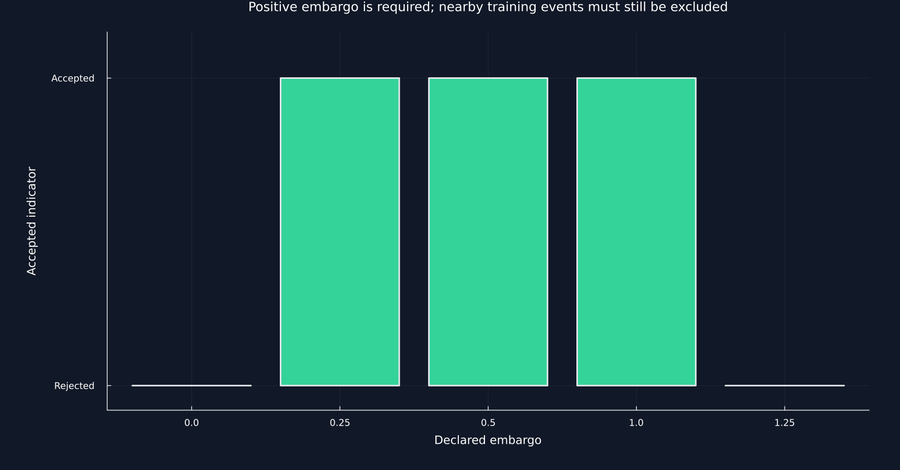

In [3]:
validation=report.variable_selection.validation
event_numbers(ids)=join([string(findfirst(==(value),observation_ids)) for value in ids],", ")
fold_table=frame(["Fold","Path","Training events","Test events","Refit record","Refit parts"],[(uppercase(fold.fold_id),uppercase(fold.path_id),event_numbers(fold.train_ids),event_numbers(fold.test_ids),uppercase(fold.refit_id),length(fold.refit_components)) for fold in validation.folds])
table(fold_table,"protocol_fold_membership")
membership=zeros(Int,length(validation.folds),length(observation_ids))
for (row,fold) in enumerate(validation.folds)
    for value in fold.train_ids
        membership[row,findfirst(==(value),observation_ids)]=1
    end
    for value in fold.test_ids
        membership[row,findfirst(==(value),observation_ids)]=-1
    end
end
save_data(hcat(DataFrame("Fold"=>uppercase.([fold.fold_id for fold in validation.folds])),DataFrame(membership,["Event "*string(index) for index in 1:6])),paths,"protocol_selection_membership")
membership_labels=map(value->value==-1 ? "Test" : value==1 ? "Train" : "",membership)
figure=heatmap_record(membership,["E"*string(index) for index in 1:6],uppercase.([fold.fold_id for fold in validation.folds]);title="Purged fold membership",xlabel="Event",ylabel="Fold",colors=[palette.rose,palette.background,palette.cyan],limits=(-1,1),labels=membership_labels)
save_figure(figure,paths,"protocol_fold_membership")
embargo_rows=[]
for embargo in [0.,.25,.5,1.,1.25]
    changed_validation=update_record(validation;embargo=embargo)
    changed_selection=update_record(report.variable_selection;validation=changed_validation)
    result=contract_case("Embargo "*string(embargo),"Stage 1",()->validate_causal_factor_protocol(update_record(report;variable_selection=changed_selection)))
    push!(embargo_rows,(embargo,result[3],result[4],!result[5]))
end
embargo_table=frame(["Embargo","Result","Message","Accepted"],embargo_rows)
table(embargo_table,"protocol_embargo_sweep")
figure=colored_bars(1:5,Int.(embargo_table.Accepted),ifelse.(embargo_table.Accepted,palette.green,palette.rose);xticks=(1:5,string.(embargo_table.Embargo)),yticks=([0,1],["Rejected","Accepted"]),ylims=(-.08,1.15),xlabel="Declared embargo",ylabel="Accepted indicator",title="Positive embargo is required; nearby training events must still be excluded",titlefontsize=11,label="",size=(1150,600))
save_figure(figure,paths,"protocol_embargo_sweep")


## Foldwise Variable Selection

A selection rule must be fitted again inside each training fold:

$$
\widehat{\mathcal V}_k=\mathcal A_{\mathrm{select}}(D_{\mathcal T_k}),
\qquad
D_{\mathcal T_k}\cap D_{\mathcal V_k}=\varnothing.
$$

Here, $\widehat{\mathcal V}_k$ is the variable set selected in fold $k$; $\mathcal A_{\mathrm{select}}$ is the declared selection rule; $D_{\mathcal T_k}$ contains training observations; $D_{\mathcal V_k}$ contains test observations; and the empty intersection states that fitting and testing use disjoint memberships.

Row,Selection method,Declared,Temporal refit required
,String,String,String
1,Mutual Information,Yes,No
2,Shapley Values,Yes,No
3,Mean Decrease Impurity,Yes,No
4,Permutation Feature Importance,Yes,Yes


Row,Fold,Refit record,Part refitted,Required in Stage 1
,String,String,String,String
1,F1,R1,Variable Selection,Yes
2,F1,R1,Causal Estimation,No
3,F1,R1,Portfolio Construction,No
4,F2,R2,Variable Selection,Yes
5,F2,R2,Causal Estimation,No
6,F2,R2,Portfolio Construction,No
7,F3,R3,Variable Selection,Yes
8,F3,R3,Causal Estimation,No
9,F3,R3,Portfolio Construction,No


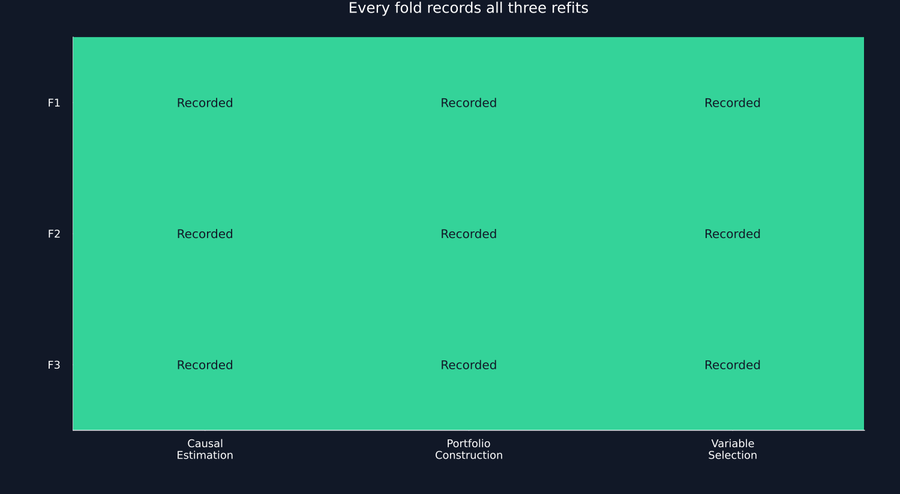

In [4]:
selection_methods=frame(["Selection method","Declared","Temporal refit required"],[(human_label(value),true,value=="PERMUTATION_FEATURE_IMPORTANCE") for value in report.variable_selection.method_labels])
table(selection_methods,"protocol_selection_methods")
refit_table=frame(["Fold","Refit record","Part refitted","Required in Stage 1"],[(uppercase(fold.fold_id),uppercase(fold.refit_id),human_label(component),component=="VARIABLE_SELECTION") for fold in validation.folds for component in fold.refit_components])
table(refit_table,"protocol_selection_refits")
refit_labels=sort(unique(refit_table[:,"Part refitted"]))
refit_matrix=[sum((refit_table.Fold.==fold).&(refit_table[:,"Part refitted"].==part)) for fold in sort(unique(refit_table.Fold)),part in refit_labels]
figure=heatmap_record(refit_matrix,replace.(refit_labels," "=>"\n"),sort(unique(refit_table.Fold));title="Every fold records all three refits",colors=[palette.background,palette.green],labels=ifelse.(refit_matrix.>0,"Recorded","Missing"))
save_figure(figure,paths,"protocol_selection_refits")


## Declaring assumptions behind graph discovery

The discovery record states a directed graph and the assumptions used to orient it:

$$
\mathcal G=(\mathcal V,\mathcal E),
\qquad
\mathcal E\subseteq \mathcal V\times\mathcal V,
\qquad
\mathcal G\ \text{contains no directed cycle}.
$$

Here, $\mathcal G$ is the declared causal graph; $\mathcal V$ is its node set; $\mathcal E$ is its directed-edge set; an ordered pair in $\mathcal E$ points from a proposed cause to a proposed effect; and the final condition makes the graph acyclic.

Row,From,To,Directed claim
,String,String,String
1,Z,X,Z to X
2,Z,Y,Z to Y
3,I,X,I to X
4,X,M,X to M
5,M,Y,M to Y
6,X,Y,X to Y
7,X,C,X to C
8,Y,C,Y to C
9,X,D,X to D


Row,Assumption,Statement
,Int64,String
1,1,The recorded variables are sufficient for the target effect.
2,2,Directions use time order and economic restrictions.


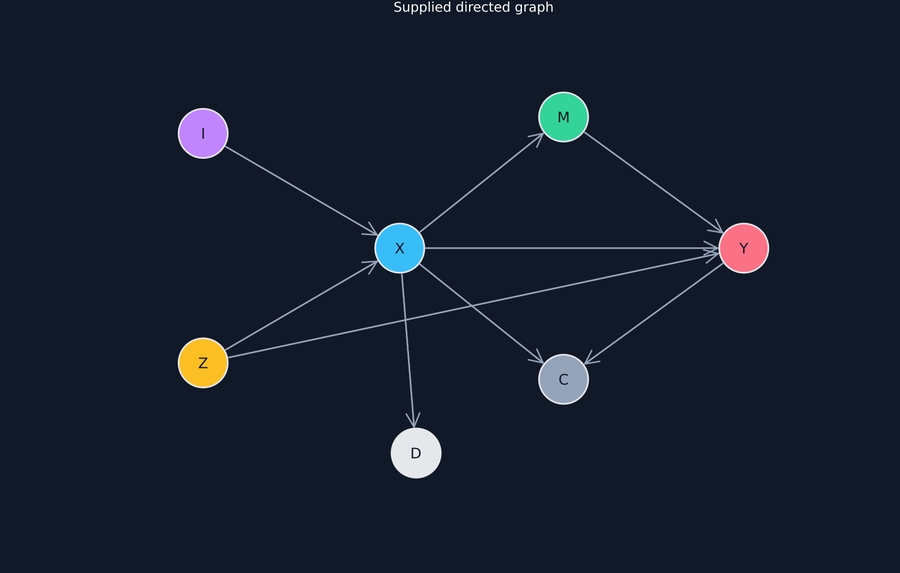

In [5]:
discovery=report.causal_discovery
graph_table=frame(["From","To","Directed claim"],[(source,target,source*" to "*target) for (source,target) in discovery.directed_edges])
table(graph_table,"protocol_graph_edges")
assumption_table=frame(["Assumption","Statement"],[(index,statement) for (index,statement) in enumerate(discovery.assumptions)])
table(assumption_table,"protocol_graph_assumptions")
save_figure(draw_causal_graph(discovery.directed_edges),paths,"protocol_causal_graph")


## Choosing adjustment roles before estimation

A valid back-door set identifies the intervention distribution through observed conditional distributions:

$$
p(y\mid\operatorname{do}(x))=\sum_z p(y\mid x,z)p(z).
$$

Here, $x$ is the treatment value; $y$ is the outcome value; $z$ ranges over a valid adjustment set; $\operatorname{do}(x)$ denotes intervention; $p(y\mid x,z)$ is the observed conditional outcome distribution; and $p(z)$ is the observed distribution of the adjustment variables.

Row,Variable,Graph role,Used as ordinary control
,String,String,String
1,X,Treatment,No
2,Y,Outcome,No
3,Z,Confounder,Yes
4,M,Mediator,No
5,C,Collider,No
6,M,Descendant,No
7,C,Descendant,No
8,D,Descendant,No
9,I,Instrument,No


Row,Item,Value
,String,Any
1,Identification method,Backdoor Adjustment
2,Identified,Yes
3,Admissible sets,Z
4,Selected set,Z
5,Open back-door paths,0
6,Control reason,Common cause of factor and return.


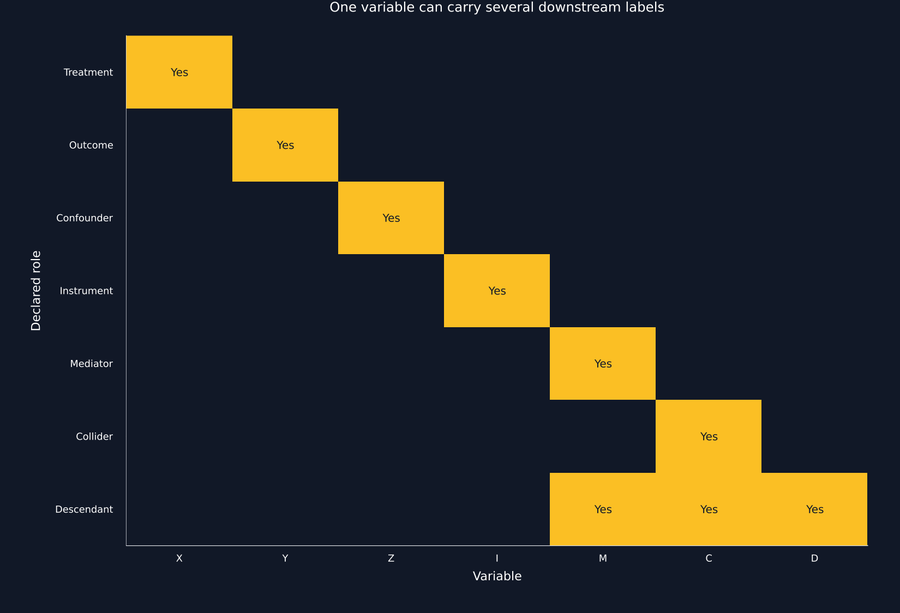

In [6]:
adjustment=report.causal_adjustment_set
role_groups=[("Treatment",(adjustment.treatment,)),("Outcome",(adjustment.outcome,)),("Confounder",adjustment.confounders),("Mediator",adjustment.mediators),("Collider",adjustment.colliders),("Descendant",adjustment.descendants),("Instrument",adjustment.instruments),("Selected control",adjustment.selected_adjustment_set)]
role_table=unique(frame(["Variable","Graph role","Used as ordinary control"],[(value,role,value in adjustment.selected_adjustment_set) for (role,values) in role_groups for value in values]))
table(role_table,"protocol_graph_roles")
identification_table=frame(["Item","Value"],[("Identification method",human_label(adjustment.method_label)),("Identified",adjustment.identified ? "Yes" : "No"),("Admissible sets",join([join(group,", ") for group in adjustment.admissible_adjustment_sets],"; ")),("Selected set",join(adjustment.selected_adjustment_set,", ")),("Open back-door paths",length(adjustment.open_backdoor_paths)),("Control reason",adjustment.control_justifications[1][2])])
table(identification_table,"protocol_adjustment_evidence")
variables=["X","Y","Z","I","M","C","D"]
roles=["Treatment","Outcome","Confounder","Instrument","Mediator","Collider","Descendant"]
declared=[Set(["X"]),Set(["Y"]),Set(["Z"]),Set(["I"]),Set(["M"]),Set(["C"]),Set(adjustment.descendants)]
role_matrix=[Int(variable in group) for group in declared,variable in variables]
save_data(hcat(DataFrame("Role"=>roles),DataFrame(role_matrix,variables)),paths,"protocol_role_matrix")
figure=heatmap_record(role_matrix,variables,roles;title="One variable can carry several downstream labels",xlabel="Variable",ylabel="Declared role",colors=[palette.background,palette.amber],labels=ifelse.(role_matrix.==1,"Yes",""),size=(1100,750))
save_figure(figure,paths,"protocol_graph_roles")


## Recording invalid graph declarations

Row,Case,Stage,Result,Message,Rejected
,String,String,String,SubStrin…,String
1,Ambiguous graph edge,Stage 2,Rejected,Stage 2: identification-relevant ambiguity must be resolved,Yes
2,Directed cycle,Stage 2,Rejected,Stage 2: the resolved graph must be acyclic,Yes
3,Selected variable absent from graph,Stage 2,Rejected,Stage 2: graph nodes must match the selected variables and outcome,Yes
4,Collider used as control,Stage 3,Rejected,"Stage 3: ordinary controls cannot include descendants, mediators, colliders, or instruments",Yes
5,Mediator used as control,Stage 3,Rejected,"Stage 3: ordinary controls cannot include descendants, mediators, colliders, or instruments",Yes
6,Descendant used as control,Stage 3,Rejected,"Stage 3: ordinary controls cannot include descendants, mediators, colliders, or instruments",Yes
7,Open back-door path,Stage 3,Rejected,Stage 3: no backdoor path may remain open,Yes


Row,Stage,Rejected cases
,String,Int64
1,Stage 2,3
2,Stage 3,4


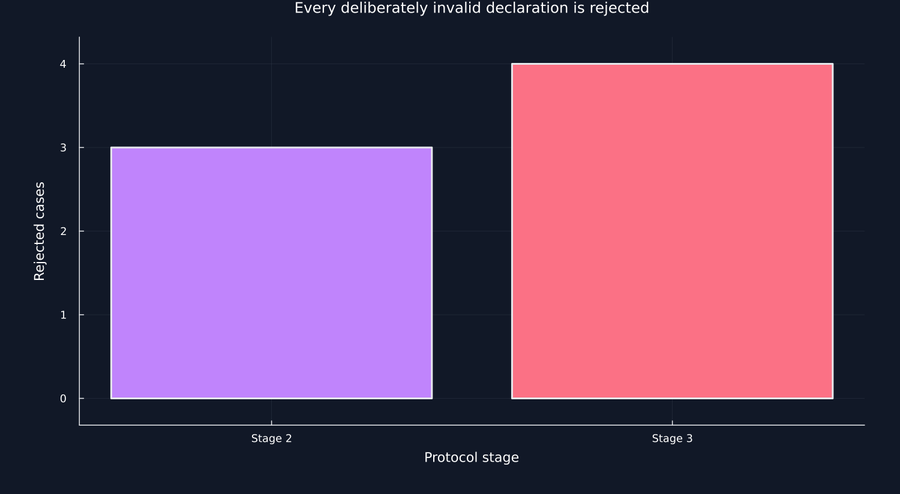

Row,Question,Evidence
,String,String
1,Was overlap stated and handled?,"Event horizons, purged folds, and embargo"
2,Was selection repeated inside training?,Distinct refit records and recorded selection refits
3,Is the graph resolved and acyclic?,"Nodes, directed edges, no ambiguous edges, and assumptions"
4,Is adjustment graph-valid?,"Admissible sets, role exclusions, reasons, and closed back-door paths"
5,Does a pass prove causal truth?,No. It proves only that the supplied record meets the structural conditions


In [7]:
invalid_rows=[]
push!(invalid_rows,contract_case("Ambiguous graph edge","Stage 2",()->validate_causal_factor_protocol(update_record(report;causal_discovery=update_record(discovery;ambiguous_edges=(("X","Y"),))))))
push!(invalid_rows,contract_case("Directed cycle","Stage 2",()->validate_causal_factor_protocol(update_record(report;causal_discovery=update_record(discovery;directed_edges=(discovery.directed_edges...,("Y","X")))))))
missing_nodes=Tuple(value for value in discovery.graph_nodes if value!="D")
missing_edges=Tuple(edge for edge in discovery.directed_edges if !("D" in edge))
push!(invalid_rows,contract_case("Selected variable absent from graph","Stage 2",()->validate_causal_factor_protocol(update_record(report;causal_discovery=update_record(discovery;graph_nodes=missing_nodes,directed_edges=missing_edges)))))
for (variable,role) in [("C","Collider used as control"),("M","Mediator used as control"),("D","Descendant used as control")]
    changed=update_record(adjustment;admissible_adjustment_sets=(("Z",variable),),selected_adjustment_set=("Z",variable),control_justifications=(("Z","Common cause."),(variable,"Invalid ordinary control.")))
    push!(invalid_rows,contract_case(role,"Stage 3",()->validate_causal_factor_protocol(update_record(report;causal_adjustment_set=changed))))
end
push!(invalid_rows,contract_case("Open back-door path","Stage 3",()->validate_causal_factor_protocol(update_record(report;causal_adjustment_set=update_record(adjustment;open_backdoor_paths=("X <- Z -> Y",))))))
invalid_table=case_frame(invalid_rows)
table(invalid_table,"protocol_stage23_rejections")
rejection_counts=combine(groupby(invalid_table,:Stage;sort=true),:Rejected=>sum=>"Rejected cases")
table(rejection_counts,"protocol_stage23_rejection_counts")
figure=colored_bars(1:2,rejection_counts[:,2],[violet,palette.rose];xticks=(1:2,rejection_counts.Stage),xlabel="Protocol stage",ylabel="Rejected cases",title="Every deliberately invalid declaration is rejected",label="",size=(1000,550))
bar_headroom!(figure,rejection_counts[:,2])
save_figure(figure,paths,"protocol_stage23_rejections")
section_summary=frame(["Question","Evidence"],[["Was overlap stated and handled?","Event horizons, purged folds, and embargo"],["Was selection repeated inside training?","Distinct refit records and recorded selection refits"],["Is the graph resolved and acyclic?","Nodes, directed edges, no ambiguous edges, and assumptions"],["Is adjustment graph-valid?","Admissible sets, role exclusions, reasons, and closed back-door paths"],["Does a pass prove causal truth?","No. It proves only that the supplied record meets the structural conditions"]])
table(section_summary,"protocol_section1_summary")


## Tests

In [8]:
@assert report.stage_names==("Variable Selection","Causal Discovery","Causal Adjustment Set","Causal Explanatory and Predictive Power","Causal Portfolio Construction","Backtest","Multiple Testing Adjustments")
@assert report.source_oracle=="PROTOCOL-01"
@assert nrow(stage_table)==7
@assert overlap[1,2]==1 && overlap[1,3]==0
@assert all(isdisjoint(Set(fold.train_ids),Set(fold.test_ids)) for fold in validation.folds)
@assert embargo_table[embargo_table.Embargo.==0.,"Accepted"]==[false]
@assert embargo_table[embargo_table.Embargo.==1.,"Accepted"]==[true]
@assert issubset(Set(report.variable_selection.selected_variables),Set(discovery.graph_nodes))
@assert adjustment.selected_adjustment_set==("Z",)
@assert all(invalid_table.Rejected)
@assert sum(rejection_counts[:,2])==nrow(invalid_table)
for name in ["protocol_stage_flow","protocol_overlap_heatmap","protocol_fold_membership","protocol_embargo_sweep","protocol_selection_refits","protocol_causal_graph","protocol_graph_roles","protocol_stage23_rejections"]
    @assert isfile(joinpath(paths.figures,name*".pdf"))
end
for name in ["protocol_stage_order","protocol_provenance","protocol_event_horizons","protocol_overlap_matrix","protocol_fold_membership","protocol_embargo_sweep","protocol_selection_methods","protocol_selection_refits","protocol_graph_edges","protocol_graph_assumptions","protocol_graph_roles","protocol_adjustment_evidence","protocol_stage23_rejections","protocol_stage23_rejection_counts","protocol_section1_summary"]
    @assert isfile(joinpath(paths.tables,name*".tex"))
end
